# Notebook 2 — O que há em um arquivo de dados do GWOSC?

**Estudo de caso: GW150914 · LIGO Hanford (H1) · Campanha O1**

### Objetivos

- Abrir o HDF5 baixado no Notebook 1 e identificar seus grupos.
- Calcular o intervalo entre amostras, a frequência de amostragem e a duração.
- Comparar o *strain* bruto antes do evento e ao redor dele.

> **Como trabalhar:** Execute as células na ordem. Nas pausas **Observe**, compare sua saída com a projetada em sala.

**Origem:** Material adaptado de [Introduction to GWOSC Data](https://github.com/gwosc-tutorial/introduction_gwosc_data), sob licença GPL-3.0 ou posterior.

**Adaptação didática:** Ronai Lisbôa — UFRN.

## Preparação 1 — Importar as bibliotecas

Use o arquivo `H-H1_LOSC_4_V1-1126256640-4096.hdf5`. Ele contém **4096 s** de dados de H1, amostrados a **4096 Hz**.

- **Colab com Drive:** coloque o HDF5 na pasta `dados` do curso no seu Google Drive. Ajuste o caminho `pasta_dados` nas células a seguir se você o salvou em outro lugar no Meu Drive.
- **Colab com arquivo na sessão:** use `pasta_dados = Path("/content")`. Envie o HDF5 pelo painel **Arquivos** caso ele ainda esteja no computador.

> **Observe:** Use `pathlib` para definir o caminho do arquivo, `h5py` para ler o HDF5, `NumPy` para trabalhar com as amostras e `Matplotlib` para gerar os gráficos.

In [4]:
# requests é uma biblioteca utilizada para realizar requisições pela internet.
# Neste curso, ela será usada para consultar a API do GWOSC e baixar arquivos.
import requests

# Exibe a versão instalada da biblioteca requests.
print("Versão do requests:", requests.__version__)


# GWpy é uma biblioteca Python desenvolvida para acessar, representar,
# visualizar e analisar dados de detectores de ondas gravitacionais.
import gwpy

# TimeSeries é uma classe do GWpy que representa dados medidos ao longo do tempo,
# como a série temporal de strain dos detectores LIGO e Virgo.
from gwpy.timeseries import TimeSeries

# Exibe a versão instalada da biblioteca GWpy.
print("Versão do GWpy:", gwpy.__version__)

# Path manipula caminhos, pastas e arquivos.
from pathlib import Path

# h5py lê arquivos HDF5; Matplotlib cria gráficos; NumPy realiza cálculos numéricos.
import h5py
import matplotlib.pyplot as plt
import numpy as np

# Define o tamanho padrão das figuras e das fontes.
plt.rcParams.update({"figure.figsize": (11, 4), "font.size": 14})

Versão do requests: 2.34.2
Versão do GWpy: 4.1.0


In [6]:
# Localizar o arquivo HDF5 na pasta atual.
pasta_dados = Path.cwd()

filename = pasta_dados / "H-H1_LOSC_4_V1-1126256640-4096.hdf5"

if not filename.exists():
    raise FileNotFoundError(
        f"Arquivo não encontrado em: {filename}"
    )

print(f"Arquivo localizado em: {filename}")

Arquivo localizado em: /Users/ronaimac/Vscode/gwd/IX SCT/H-H1_LOSC_4_V1-1126256640-4096.hdf5


## O formato HDF5

O [HDF5](https://www.hdfgroup.org/solutions/hdf5/) é um formato de armazenamento hierárquico usado em ciência. Ele organiza informações em **grupos**, semelhantes a pastas, e **datasets**, semelhantes a conjuntos de valores, além de **atributos** que descrevem esses dados.

A biblioteca [h5py](https://www.h5py.org/) permite acessar essa estrutura em Python. Existe também uma ferramenta gráfica, [HDFView](https://www.hdfgroup.org/downloads/hdfview/), mas **não é necessário instalá-la** para este curso.

<div align="center">

<img src="https://raw.githubusercontent.com/Ronai/gwd/a952e66632e1b3565d5e3f3866331d8e488bb238/introduction_gwosc_data/img/ligo%20-%20hdf5%20view.png" width="750">

</div>

*Figura 1 — Estrutura do arquivo HDF5 de Hanford (H1) no HDFView.
À esquerda, aparecem os grupos `meta`, `quality` e `strain`.*

## 1. Abrir o arquivo e identificar os grupos

Abra o HDF5 em modo de leitura (`"r"`) e liste os grupos na raiz.

> **Observe:** `meta` reúne informações sobre o arquivo, `quality` contém os indicadores de qualidade e `strain` contém a série temporal.


```python
dataFile = h5py.File(filename, "r")

print("Grupos na raiz do arquivo:")
for key in dataFile.keys():
    print(" -", key)
````
    

In [7]:
dataFile = h5py.File(filename, "r")

print("Grupos na raiz do arquivo:")
for key in dataFile.keys():
    print(" -", key)

Grupos na raiz do arquivo:
 - meta
 - quality
 - strain


## 2. Consultar os metadados

Conseguimos ler o conteúdo dos metadados dos grupos `meta`, `strain` e `quality` que estão disponíveis para usarmos em nossas análises.


### 2.1 Grupo meta

Conseguimos ler quais metadados estão disponíveis para uso no gurpo **meta**.

```python
# Metadados disponíveis no grupo 'meta'
meta = dataFile['meta']
metaKeys = meta.keys()

print(f'Metadados disponíveis ({len(metaKeys)}):\n')

for key in metaKeys:
    print(key, meta[key])
````

In [8]:
#------------------------------------
# Metadados disponíveis no grupo 'meta'
#------------------------------------
meta = dataFile['meta']
metaKeys = meta.keys()

print(f'Metadados disponíveis ({len(metaKeys)}):\n')

for key in metaKeys:
    print(key, meta[key])

Metadados disponíveis (8):

Description <HDF5 dataset "Description": shape (), type "|O">
DescriptionURL <HDF5 dataset "DescriptionURL": shape (), type "|O">
Detector <HDF5 dataset "Detector": shape (), type "|O">
Duration <HDF5 dataset "Duration": shape (), type "<i8">
GPSstart <HDF5 dataset "GPSstart": shape (), type "<i8">
Observatory <HDF5 dataset "Observatory": shape (), type "|O">
Type <HDF5 dataset "Type": shape (), type "|O">
UTCstart <HDF5 dataset "UTCstart": shape (), type "|O">


In [9]:
#------------------------------------
# Leia alguns dados do grupo meta
#------------------------------------

'''
 O grupo `meta` contém 8 metadados, cada um armazenado em um dataset escalar
 (shape ()), ou seja, com um único valor.
'''

meta = dataFile['meta']

gpsStart = int(meta['GPSstart'][()])
duration = int(meta['Duration'][()])
duration = int(meta['Duration'][()])

gpsEnd = gpsStart + duration

print(f'GPS inicial: {gpsStart}')
print(f'Duração: {duration} s')
print(f'GPS final (limite exclusivo): {gpsEnd}')

GPS inicial: 1126256640
Duração: 4096 s
GPS final (limite exclusivo): 1126260736


### 2.2 Grupo strain

Conseguimos ler quais metadados estão disponíveis para usarmos no gurpo **strain**.

```python
# Datasets disponíveis no grupo 'strain'
strain = dataFile['strain']
strainKeys = strain.keys()

print(f'Datasets disponíveis em strain ({len(strainKeys)}):\n')

for key in strainKeys:
    print(key, strain[key])
```


In [10]:
#------------------------------------
# Datasets disponíveis no grupo 'strain'
#------------------------------------

'''
O `strain` tem uma dimensão, com 16.777.216 amostras.
A vírgula indica que (16777216,) é uma tupla de um único elemento em Python.
Cada amostra é um número de ponto flutuante (f) de 8 bytes (8), ou 64 bits.
'''

strain = dataFile['strain']
strainKeys = strain.keys()

print(f'Datasets disponíveis em strain ({len(strainKeys)}):\n')

for key in strainKeys:
    print(key, strain[key])

Datasets disponíveis em strain (1):

Strain <HDF5 dataset "Strain": shape (16777216,), type "<f8">


O dataset `strain/Strain` contém a série temporal.
O atributo `Xspacing` fornece o intervalo $\Delta t$ entre amostras.
Com $N$ amostras, a frequência é $f_s=1/\Delta t$ e a duração do trecho é $N\Delta t$.

```python
# Leia alguns dados do grupo strain

df = dataFile['strain'].keys()
for key in df:
    print(key)
strain = dataFile['strain']['Strain']

ts = float(strain.attrs['Xspacing'])
fs = 1 / ts
N = strain.shape[0]
duracao = N * ts  # equivalente a N / fs

print(f'Intervalo entre amostras: {ts:.9f} s')
print(f'Frequência de amostragem: {fs:.0f} Hz')
print(f'Número de amostras: {N:,}'.replace(',', '.'))
print(f'Duração total do trecho: {duracao:.0f} s')
```

In [11]:
#------------------------------------
# Leia alguns dados do grupo strain
#------------------------------------

df = dataFile['strain'].keys()
for key in df:
    print(key)
strain = dataFile['strain']['Strain']

ts = float(strain.attrs['Xspacing'])
fs = 1 / ts
N = strain.shape[0]
duracao = N * ts  # equivalente a N / fs

print(f'Intervalo entre amostras: {ts:.9f} s')
print(f'Frequência de amostragem: {fs:.0f} Hz')
print(f'Número de amostras: {N:,}'.replace(',', '.'))
print(f'Duração total do trecho: {duracao:.0f} s')

Strain
Intervalo entre amostras: 0.000244141 s
Frequência de amostragem: 4096 Hz
Número de amostras: 16.777.216
Duração total do trecho: 4096 s


## 3. Visualizar a série temporal por trechos

Vamos desenhar **16,8 milhões de pontos** de uma só vez. O tempo de cada amostra é dado por

$$
t_i = t_{\mathrm{GPS,início}} + i\,\Delta t,
$$

em que $\Delta t=1/f_s$ e $i$ é o índice da amostra.

```python
# Como queremos montar o vetor tempo, podemos extrair desses dados:
gpsStart = meta['GPSstart'][()]
duration = meta['Duration'][()]
gpsEnd   = gpsStart + duration

time = np.arange(gpsStart, gpsEnd, ts) # Criamos o vetor de tempo com incremento de ts

# Fazemos o gráfico do nosso vetor tempo pela variação strain
plt.plot(time, strain[()])
plt.xlabel('GPS Time (s)')
plt.ylabel('H1 Strain')
plt.show()
```


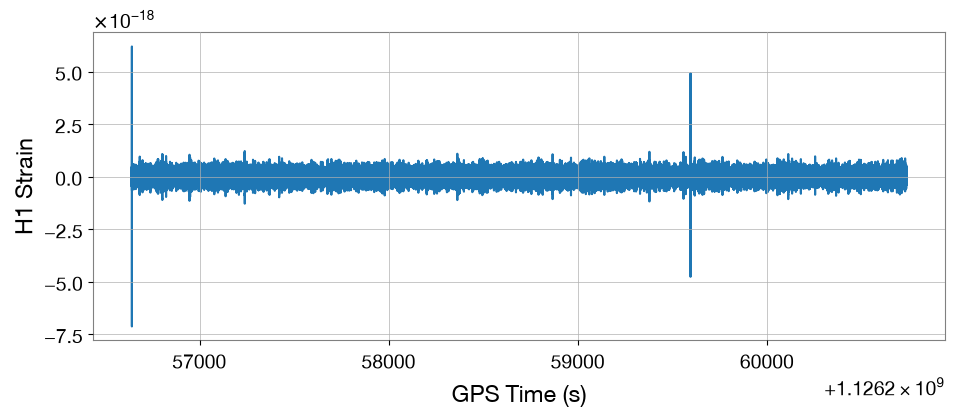

In [12]:
# Como queremos montar o vetor tempo, podemos extrair desses dados:
gpsStart = meta['GPSstart'][()]
duration = meta['Duration'][()]
gpsEnd   = gpsStart + duration

time = np.arange(gpsStart, gpsEnd, ts) # Criamos o vetor de tempo com incremento de ts


# Fazemos o gráfico do nosso vetor tempo pela variação strain
plt.plot(time, strain[()])
plt.xlabel('GPS Time (s)')
plt.ylabel('H1 Strain')
plt.show()

## 4. Observar o strain bruto antes do evento

Cada amostra de índice $i$ foi registrada em $t_i = t_0 + i\,\Delta t$. Nos gráficos, usaremos o tempo relativo ao evento, $t_i-t_{\mathrm{GW}}$.

O $t_0$ marca o GPS **1126259462,4** do evento GPS_EVENTO = 1126259462.4.

Ao contrário de carregar o arquivo completo com cerca de **16,8 milhões de amostras**, nós podemos fatiá-lo `strain[i0:i1]` e carregar apenas o trecho a ser mostrado.

Primeiro, vamos observar **10 segundos** da série temporal, antes do evento. O objetivo é reconhecer as oscilações e o ruído presentes no *strain* bruto.

```python
GPS_EVENTO = 1126259462.4

inicio_visao = GPS_EVENTO - 20.0  # 20 segundos antes do evento
duracao_visao = 10.0

i0 = int(round((inicio_visao - gpsStart) * fs))
i1 = i0 + int(round(duracao_visao * fs))

if not (0 <= i0 < i1 <= N):
    raise ValueError('Intervalo escolhido fora da duração do arquivo.')

tempo_visao = (gpsStart - GPS_EVENTO) + np.arange(i0, i1) * ts
strain_visao = strain[i0:i1]

plt.figure(layout="constrained")
plt.plot(tempo_visao, strain_visao, linewidth=0.6)
plt.xlabel('Tempo relativo ao GW150914 (s)')
plt.ylabel('Strain H1')
plt.title('Dados brutos do H1. 20 a 10 s antes do GW150914')
plt.grid(alpha=0.25)
plt.show()
```


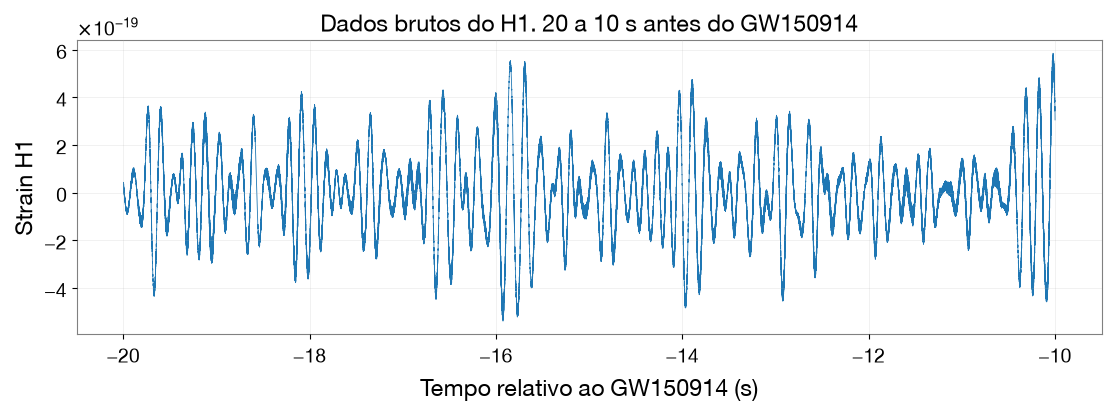

In [13]:
GPS_EVENTO = 1126259462.4

inicio_visao = GPS_EVENTO - 20.0  # 20 segundos antes do evento
duracao_visao = 10.0

i0 = int(round((inicio_visao - gpsStart) * fs))
i1 = i0 + int(round(duracao_visao * fs))

if not (0 <= i0 < i1 <= N):
    raise ValueError('Intervalo escolhido fora da duração do arquivo.')

tempo_visao = (gpsStart - GPS_EVENTO) + np.arange(i0, i1) * ts
strain_visao = strain[i0:i1]

plt.figure(layout="constrained")
plt.plot(tempo_visao, strain_visao, linewidth=0.6)
plt.xlabel('Tempo relativo ao GW150914 (s)')
plt.ylabel('Strain H1')
plt.title('Dados brutos do H1. 20 a 10 s antes do GW150914')
plt.grid(alpha=0.25)
plt.show()

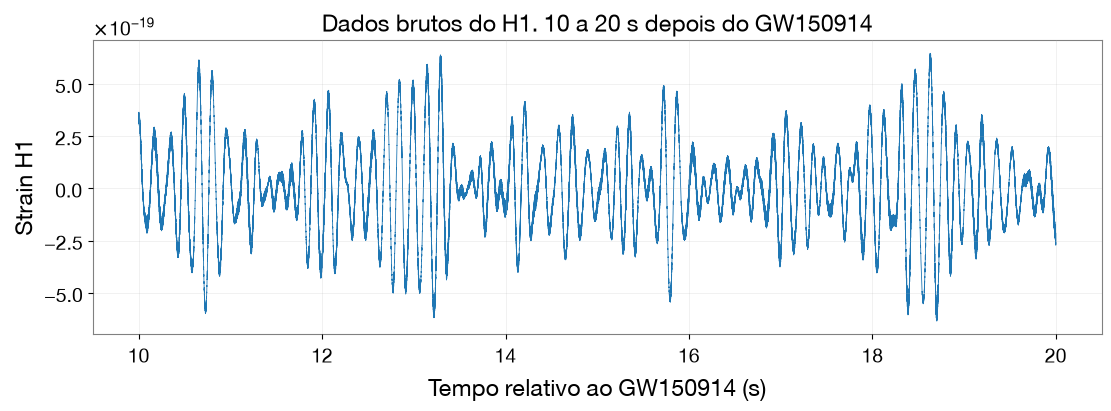

In [14]:
GPS_EVENTO = 1126259462.4

inicio_visao = GPS_EVENTO + 10.0  # 10 segundos depois do evento
duracao_visao = 10.0

i0 = int(round((inicio_visao - gpsStart) * fs))
i1 = i0 + int(round(duracao_visao * fs))

if not (0 <= i0 < i1 <= N):
    raise ValueError('Intervalo escolhido fora da duração do arquivo.')

tempo_visao = (gpsStart - GPS_EVENTO) + np.arange(i0, i1) * ts
strain_visao = strain[i0:i1]

plt.figure(layout="constrained")
plt.plot(tempo_visao, strain_visao, linewidth=0.6)
plt.xlabel('Tempo relativo ao GW150914 (s)')
plt.ylabel('Strain H1')
plt.title('Dados brutos do H1. 10 a 20 s depois do GW150914')
plt.grid(alpha=0.25)
plt.show()

## 5. Ampliar a janela do GW150914

Agora, vamos selecionar um intervalo de **2,4 segundos**, centrado aproximadamente no instante do GW150914. Isso permite investigar a vizinhança temporal do evento **sem carregar o arquivo inteiro na memória**.

```python
inicio_visao = GPS_EVENTO - 1.2  # 1,2 s antes do evento
duracao_visao = 2.4             # 1,2 s antes + 1,2 s depois

i0 = int(round((inicio_visao - gpsStart) * fs))
i1 = i0 + int(round(duracao_visao * fs))

if not (0 <= i0 < i1 <= N):
    raise ValueError('Intervalo escolhido fora da duração do arquivo.')

tempo_visao = (gpsStart - GPS_EVENTO) + np.arange(i0, i1) * ts
strain_visao = strain[i0:i1]

plt.figure(layout="constrained")
plt.plot(tempo_visao, strain_visao, linewidth=0.6)
plt.axvline(0, linestyle='--', label='Instante do GW150914')
plt.xlabel('Tempo relativo ao GW150914 (s)')
plt.ylabel('Strain H1')
plt.title('Dados brutos do H1. De −1,2 s a +1,2 s em torno do GW150914')
plt.legend()
plt.grid(alpha=0.25)
plt.show()
```


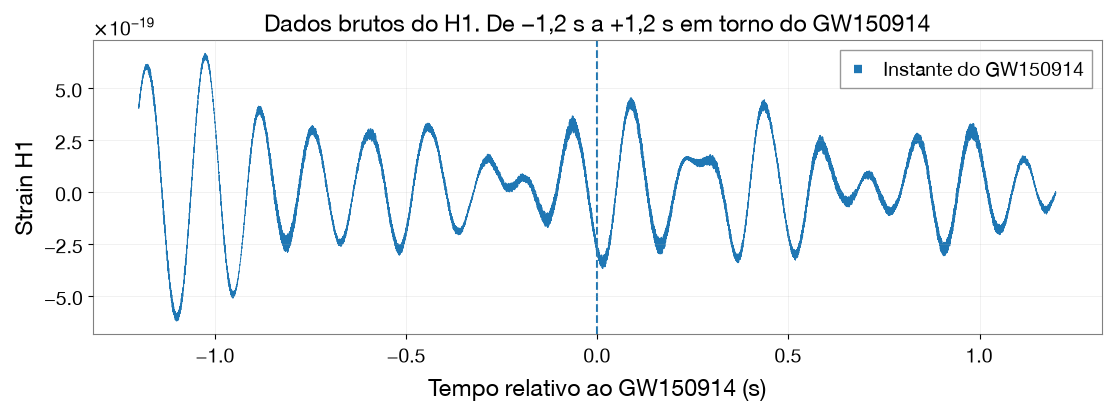

In [15]:
inicio_visao = GPS_EVENTO - 1.2  # 1,2 s antes do evento
duracao_visao = 2.4             # 1,2 s antes + 1,2 s depois

i0 = int(round((inicio_visao - gpsStart) * fs))
i1 = i0 + int(round(duracao_visao * fs))

if not (0 <= i0 < i1 <= N):
    raise ValueError('Intervalo escolhido fora da duração do arquivo.')

tempo_visao = (gpsStart - GPS_EVENTO) + np.arange(i0, i1) * ts
strain_visao = strain[i0:i1]

plt.figure(layout="constrained")
plt.plot(tempo_visao, strain_visao, linewidth=0.6)
plt.axvline(0, linestyle='--', label='Instante do GW150914')
plt.xlabel('Tempo relativo ao GW150914 (s)')
plt.ylabel('Strain H1')
plt.title('Dados brutos do H1. De −1,2 s a +1,2 s em torno do GW150914')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

> **Observe:** O que você consegue identificar perto da linha tracejada?

A linha marca o instante conhecido do GW150914.

**O sinal gravitacional aparece claramente?** Não necessariamente. O *strain* bruto é dominado por ruído de origem instrumental e ambiental, que depende fortemente da frequência (é um **ruído colorido**, diferente do [ruído branco](https://en.wikipedia.org/wiki/White_noise)). Assim, observar a janela que contém o evento **não significa** que o *chirp* já esteja visível.

Você pode se surpreender ao ver que os dados parecem suaves e curvilíneos, em vez de irregulares e instáveis, como se poderia esperar para [ruído branco](https://en.wikipedia.org/wiki/White_noise).
Isso ocorre porque o ruído branco tem potência aproximadamente igual em todas as frequências, o que não acontece com os dados de ondas gravitacionais.
Em vez disso, os dados de ondas gravitacionais incluem ruído que é fortemente dependente da frequência - costumamos dizer que o ruído é "colorido" para distingui-lo do ruído branco.
As oscilações que você vê no gráfico acima estão na extremidade inferior da banda LVK (em torno de 20 Hz).

Em geral, o ruído de ondas gravitacionais é dominado por essas baixas frequências.

Nos notebooks seguintes serão estudadas a qualidade dos dados, a análise no domínio da frequência e técnicas de filtragem que ajudam a evidenciar o sinal.

## 6. Exploração opcional

## 6.1 estrutura interna completa

O método [`visititems`](https://docs.h5py.org/en/stable/high/group.html#h5py.Group.visititems) permite percorrer a hierarquia do arquivo. Em vez de imprimir os milhões de valores do *strain*, mostramos apenas o nome e a forma (*shape*) de cada conjunto de dados.

In [16]:
def mostrar_estrutura(nome, obj):
    if isinstance(obj, h5py.Dataset):
        print(f'{nome}: dataset; shape={obj.shape}; dtype={obj.dtype}')
    else:
        print(f'{nome}: grupo')

dataFile.visititems(mostrar_estrutura)

meta: grupo
meta/Description: dataset; shape=(); dtype=object
meta/DescriptionURL: dataset; shape=(); dtype=object
meta/Detector: dataset; shape=(); dtype=object
meta/Duration: dataset; shape=(); dtype=int64
meta/GPSstart: dataset; shape=(); dtype=int64
meta/Observatory: dataset; shape=(); dtype=object
meta/Type: dataset; shape=(); dtype=object
meta/UTCstart: dataset; shape=(); dtype=object
quality: grupo
quality/detail: grupo
quality/injections: grupo
quality/injections/InjDescriptions: dataset; shape=(5,); dtype=|S29
quality/injections/InjShortnames: dataset; shape=(5,); dtype=|S17
quality/injections/Injmask: dataset; shape=(4096,); dtype=uint32
quality/simple: grupo
quality/simple/DQDescriptions: dataset; shape=(7,); dtype=|S24
quality/simple/DQShortnames: dataset; shape=(7,); dtype=|S10
quality/simple/DQmask: dataset; shape=(4096,); dtype=uint32
strain: grupo
strain/Strain: dataset; shape=(16777216,); dtype=float64


## 6.2 GWpy

A biblioteca do GWpy permite carregar os dados diretamente como uma TimeSeries, sem precisar administrar manualmente a URL, mas tem a desvantagem de não salvar o arquivo hdf5 e explorá-lo.

In [20]:
from gwpy.timeseries import TimeSeries

gps_start = GPS_EVENTO                # 1126256640
gps_end = gps_start + 4096

strain = TimeSeries.fetch_open_data(
    "H1",
    gps_start,
    gps_end,
    sample_rate=4096,
    format="hdf5",
    cache=True,        #faz o GWpy manter uma cópia local no cache da sessão
    verbose=True
)

print(strain)
print(f"GPS inicial: {strain.t0}")
print(f"Frequência de amostragem: {strain.sample_rate}")
print(f"Número de amostras: {strain.size:,}".replace(",", "."))
print(f"Duração: {strain.duration}")

TimeSeries([-2.64076922e-19, -2.95929189e-19, -2.94362862e-19,
            ..., -2.72805088e-20, -6.31917439e-21,
             1.98081191e-20],
           unit: dimensionless,
           dtype: float64,
           t0: 1126259462.3999023 s,
           dt: 0.000244140625 s,
           name: H1:Strain,
           channel: None)
GPS inicial: 1126259462.3999023 s
Frequência de amostragem: 4096.0 Hz
Número de amostras: 16.777.216
Duração: 4096.0 s


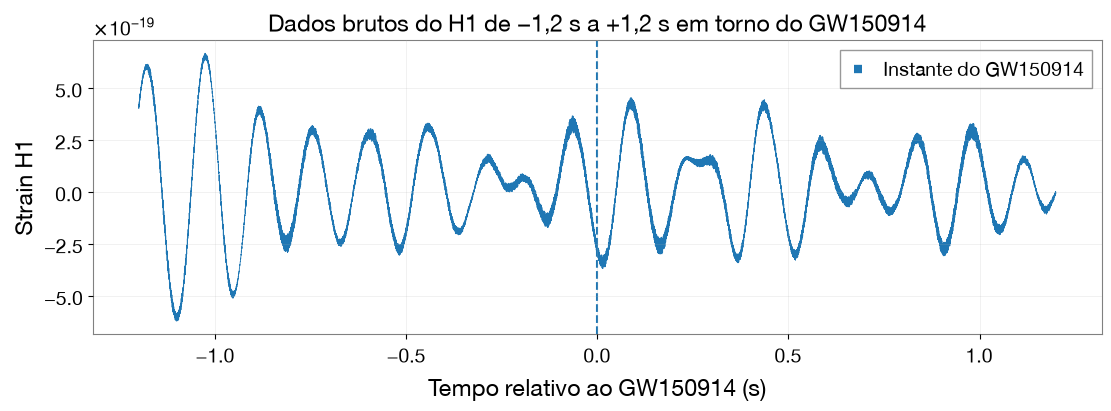

In [ ]:
from gwpy.timeseries import TimeSeries

inicio_visao = GPS_EVENTO - 1.2  # 1,2 s antes do evento
duracao_visao = 2.4              # 1,2 s antes + 1,2 s depois

i0 = int(round((inicio_visao - gpsStart) * fs))
i1 = i0 + int(round(duracao_visao * fs))

if not (0 <= i0 < i1 <= N):
    raise ValueError('Intervalo escolhido fora da duração do arquivo.')

# Cria uma série temporal do GWpy com as amostras da janela.
trecho = TimeSeries(
    strain[i0:i1],
    t0=gpsStart + i0 * ts,
    dt=ts,
    name='Strain H1',
)

tempo_relativo = trecho.times.value - GPS_EVENTO

plt.figure(layout='constrained')
plt.plot(tempo_relativo, trecho.value, linewidth=0.6)
plt.axvline(0, linestyle='--', label='Instante do GW150914')
plt.xlabel('Tempo relativo ao GW150914 (s)')
plt.ylabel('Strain H1')
plt.title('Dados brutos do H1 de −1,2 s a +1,2 s em torno do GW150914')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 7. Verificação e exercícios

1. Quais são os três grupos principais encontrados no arquivo? Qual deles contém os dados de *strain*?
2. Qual é a diferença entre o instante GPS inicial do arquivo e o instante do GW150914? O que cada instante representa?
3. Confirme, com o tamanho de `strain` e o valor de `ts`, o número de amostras calculado no Notebook 01.
4. Compare as duas janelas. Que papel o ruído desempenha na identificação do sinal?

**Registre as respostas em uma célula de texto.**

In [ ]:
# Ao terminar a exploração, feche o arquivo para liberar o recurso.
dataFile.close()
print('Arquivo HDF5 fechado.')

Arquivo HDF5 fechado.


## Próxima etapa

No **Notebook 03 — Qualidade dos Dados**, examinaremos os indicadores que descrevem os períodos de operação e a qualidade dos dados dos detectores. Depois, no **Notebook 04 — Domínio da Frequência**, veremos por que o ruído se comporta de maneira diferente nas várias frequências e como isso afeta a busca por sinais gravitacionais.

Este notebook manteve os conceitos e as referências do tutorial original, com adaptações para o arquivo **H1/O1** que contém o **GW150914**.